In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
repo_root = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.exists("../common") else os.path.abspath(os.getcwd())
if "google.colab" in sys.modules:
    print("⚡ Google Colab 環境を検出しました。リポジトリのセットアップを開始します...")
    !git clone https://github.com/miyayudai/study-mikanos.git /content/study-mikanos 2>/dev/null || (cd /content/study-mikanos && git pull)
    %cd /content/study-mikanos
    !pip install -q -r requirements.txt
    !pip install -q -e .
    repo_root = "/content/study-mikanos"
    sys.path.insert(0, repo_root)
    print("✅ 環境セットアップが完了しました。作業ディレクトリ:", os.getcwd())
else:
    if repo_root not in sys.path:
        sys.path.insert(0, repo_root)
    print("💻 ローカル・開発環境で実行中。リポジトリルート:", repo_root)


💻 ローカル・開発環境で実行中。リポジトリルート: /home/student/Documents/GitHub/study-mikanos


# 8.1 メモリ管理 (`Role of OS Memory Management`)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miyayudai/study-mikanos/blob/main/8/8.1_Role_of_OS_Memory_Management.ipynb)
![Language](https://img.shields.io/badge/Language-C%2B%2B20%20%7C%20Python%203.11%2B-blue.svg)
![Target](https://img.shields.io/badge/Target-x86__64%20%7C%20PMM%20%7C%20VMM-orange.svg)
![Status](https://img.shields.io/badge/Status-Completed-brightgreen.svg)

---

## 🎯 本節の目的と学習到達目標

第7章までの MikanOS では、ピクセル描画・文字描画・マウス入力・割り込み処理（IDT・MSI）・イベントキュー（`ArrayQueue`）といった GUI/イベント駆動の基本基盤を順調に構築してきました。

しかし、**「メモリ（RAM）」** については、依然としてブートローダが UEFI ファームウェアから割り当ててもらった領域や、コンパイラがカーネル実行ファイル（ELF）のセグメントとして静的に配置した領域をそのまま使っているに過ぎません。

本節（8.1節）では、**「なぜ OS は自前でメモリ管理機構を持たなければならないのか」** という根本的な動機を出発点として、以下の現代 OS のメモリ管理アーキテクチャの理論と数理を徹底的に解剖します：

1. **UEFI Boot Services の終焉と OS 自前メモリ管理の必然性**:
   - `ExitBootServices()` 呼び出し以降、なぜファームウェアのメモリ機能に頼れなくなるのか
2. **物理メモリ管理 (PMM: Physical Memory Management)**:
   - 4 KiB ページフレーム（Page Frame）単位の分割、ページフレーム番号（PFN）の数理
   - ビットマップ管理（Bitmap）、フリーリスト（Free List）、バディシステム（Buddy System）の空間オーバヘッド・計算量・断片化特性の比較
3. **仮想メモリ管理 (VMM: Virtual Memory Management) と MMU**:
   - 物理アドレスと仮想アドレスの分離、プロセス分離、メモリ保護属性（Read/Write/Execute、Ring 0/3 特権分離）
   - x86-64 の 4階層ページング（PML4, PDP, PD, PT）と 48ビット正規アドレス分解
4. **MikanOS 第8章「メモリ管理」の全体ロードマップ**:
   - 8.1節から8.7節（`BitmapMemoryManager`）に至るベアメタル上でのメモリサブシステム構築パイプライン


---

## 1. なぜ OS 自前のメモリ管理が必要なのか？（UEFI Boot Services の終焉）

### 1.1 第7章までのメモリ利用の実態

第7章までの MikanOS のコードを振り返ると、変数やデータ構造は以下のように配置されていました：

1. **グローバル変数**: `main.cpp` のファイルスコープに静的に置かれた変数（BSS / Data セグメント）。
2. **ローカル変数**: 関数のスタックフレーム上（UEFI ファームウェアがブートローダに与えたスタック領域）。
3. **動的バッファ**: `main.cpp` で固定長配列として確保された `mouse_cursor_buf` や `ArrayQueue`。

この段階では、**「メモリが欲しいときに動的にサイズを決めて確保する（`malloc` や `new`）」** という操作が一切できませんでした。

### 1.2 `ExitBootServices()` の呼出とファームウェア管理の喪失

ブートローダ（`MikanLoaderPkg/Main.c`）の起動時には、UEFI が提供する **Boot Services** を利用してメモリを割り当てることができました：

```c
// UEFI ブートローダ内でのみ利用可能だったメモリ割り当て関数
gBS->AllocatePages(AllocateAnyPages, EfiLoaderData, num_pages, &addr);
gBS->AllocatePool(EfiLoaderData, size, &buffer);
```

しかし、第3章で解説した通り、ブートローダはカーネルを起動する直前に **`gBS->ExitBootServices()`** を呼び出しています。

> [!WARNING]
> **`ExitBootServices()` 呼出後の致命的制約**:
> `ExitBootServices()` が成功した瞬間、UEFI の Boot Services コード領域およびデータ領域は解放対象となり、**すべての UEFI メモリ割り当て API（`AllocatePages`, `AllocatePool` 等）は恒久的に使用不可能** になります（呼べば CPU 例外またはハングが発生します）。
> 残存するのは時刻取得や NVRAM 変数アクセスなど最小限の Runtime Services のみです。

したがって、OS カーネルが今後、可変サイズのデータ構造（マルチウィンドウ、動的レイヤ、ファイルバッファ、タスク管理リスト）を扱うためには、**OS カーネル自身がマシン上の物理 RAM の空き状況を把握し、自前でメモリの割り当てと解放を差配する「物理メモリマネージャ (PMM)」を構築する以外に道はありません**。

### 1.3 複数アプリケーションの実行とメモリ保護の要求

さらに将来の章（第18章以降）では、OS 上で複数のユーザーアプリケーションを起動します。
もしメモリ管理機構がなければ、以下のような致命的な問題が発生します：

- **メモリの衝突・破壊**: アプリ A が `0x100000` に書き込んだデータを、直後に起動したアプリ B が上書きしてしまう。
- **カーネル領域の汚染**: バグのあるアプリや悪意のあるプログラムが、OS カーネルのスタックや IDT、PCI レジスタ領域を不正に書き換えてマシンをクラッシュさせる。
- **特権昇格の防止**: アプリケーション（Ring 3 ユーザーモード）から OS カーネル（Ring 0 スーパーバイザモード）のメモリへの勝手な読み書きをハードウェアレベルで完全に遮断する。

これらを実現するのが、**「物理メモリ管理 (PMM)」** と **「仮想メモリ管理 (VMM / ページング)」** の協調です。


---

## 2. 物理メモリ管理 (PMM: Physical Memory Management) の基礎数理

### 2.1 4 KiB ページフレーム（Page Frame）の分割

現代の x86-64 プロセッサにおいて、物理メモリ（Physical RAM）はバイト単位ではなく、**4 KiB（4,096 バイト = $2^{12}$ バイト）** の固定サイズブロックに区切って管理するのが最も一般的です。
この 4 KiB の物理メモリ区画を **「ページフレーム（*Page Frame*）」** と呼びます。

#### 物理アドレスからページフレーム番号（PFN）への変換数理

64ビットの物理アドレス $A_{phys}$ が与えられたとき、ページフレーム番号 $	ext{PFN}$（*Page Frame Number*）およびページ内オフセット $	ext{Offset}$ は以下のビット演算で一意に求まります：

$$	ext{PFN} = \lfloor A_{phys} / 4096 floor = A_{phys} \gg 12$$

$$	ext{Offset} = A_{phys} \pmod{4096} = A_{phys} \ \& \ 	ext{0xFFF}$$

$$A_{phys} = (	ext{PFN} \ll 12) \ | \ 	ext{Offset}$$

- 4 KiB 境界に整列したアドレス（**ページアライメント / *Page Aligned***）では、下位 12 ビット（$	ext{Offset}$）が常にすべてゼロ（`0x000`）となります。

### 2.2 物理メモリアロケータアルゴリズムの比較

物理ページフレームの空き状態を管理する代表的なアルゴリズムには、以下の 3 つがあります：

| 管理方式 | データ構造 | 空間オーバヘッド | 1ページ確保計算量 | 1ページ解放計算量 | 断片化特性 | MikanOS での採否 |
|:---|:---|:---:|:---:|:---:|:---|:---:|
| **ビットマップ方式 (`Bitmap`)** | 1ビットで1フレームを表すビット配列 | **約 0.003% (固定)** | $O(N)$ (First-Fit) | **$O(1)$ (即時ビットクリア)** | 内部断片化なし、外部断片化中 | **採用 (`BitmapMemoryManager`)** |
| **フリーリスト方式 (`Free List`)** | 空き領域の連結リスト (ノード構造体) | 変動 (空きブロック数 $	imes$ 24B) | $O(M)$ (線形探索) | $O(1)$ または $O(M)$ | 外部断片化大 | 不採用 |
| **バディシステム (`Buddy System`)** | $2^k$ べき乗ブロックの二分木 | 約 1〜2% (木・オーダー管理) | $O(\log N)$ | $O(\log N)$ (相棒結合) | 内部断片化大 ($2^k$ 切り上げ) | 将来の拡張候補 (Linux等) |

### 2.3 ビットマップ方式の驚異的な省メモリ性（導出）

ビットマップ方式では、4 KiB（4,096 バイト）の物理フレーム 1 つの「空き（0） / 使用中（1）」を **たったの 1 ビット** で表現します。

$$R_{overhead} = rac{1 	ext{ bit}}{4096 	ext{ bytes}} = rac{1 	ext{ bit}}{4096 	imes 8 	ext{ bits}} = rac{1}{32768} pprox 0.000030517 \ (0.00305\%)$$

- **4 GiB の RAM** を管理する場合：
  $$	ext{総フレーム数} = rac{4 	imes 1024^3 	ext{ B}}{4096 	ext{ B}} = 1,048,576 	ext{ frames}$$
  $$	ext{ビットマップサイズ} = rac{1,048,576 	ext{ bits}}{8 	ext{ bits/byte}} = 131,072 	ext{ bytes} = \mathbf{128 	ext{ KiB}}$$

4 GiB もの広大な物理メモリ空間を、わずか **128 KiB** のメモリで完全に管理できるのです。
この圧倒的なシンプルさと省メモリ性、そしてヒープ（`malloc`）が存在しない初期カーネル起動時から静的配列（BSS セグメント）として即座に稼働できる点こそが、MikanOS で `BitmapMemoryManager` が選定された最大の理由です。


/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:29269: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


✅ Figure 8.02 を生成・保存しました: result/fig8_02_memory_management_data_structures_comparison.png


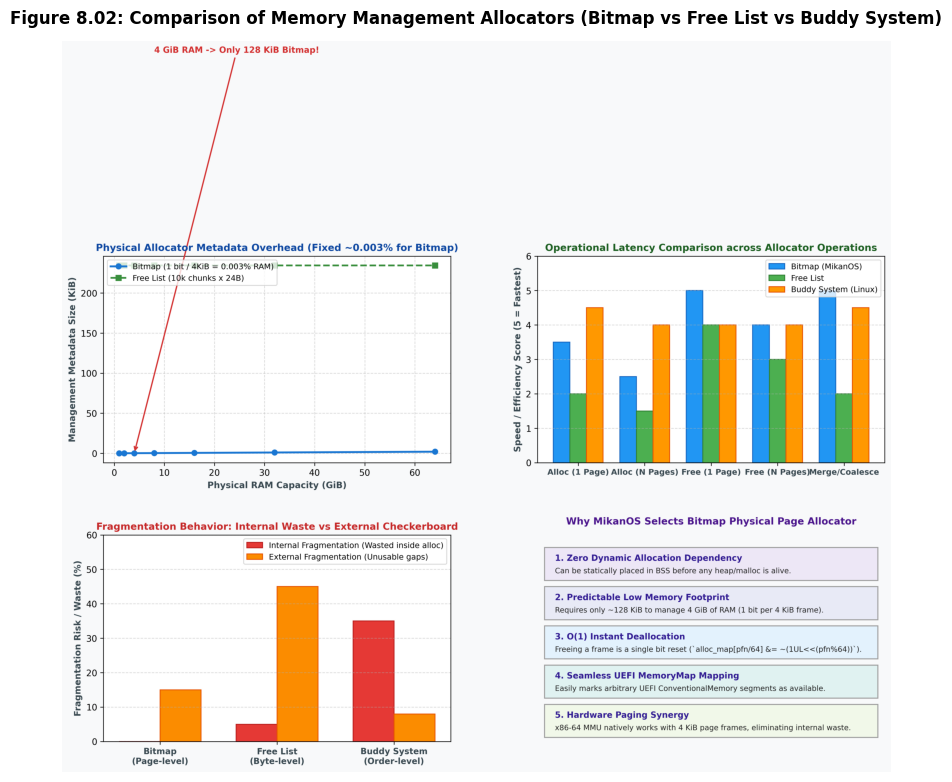

In [2]:
# === Figure 8.02: メモリ管理データ構造の比較とオーバヘッド・計算量分析 ===
import matplotlib.pyplot as plt
from common import (
    MemoryAllocationStrategyComparator,
    plot_fig8_02_memory_management_data_structures_comparison
)

# 1. 高解像度プロット生成 (DPI 300)
fig2_path = plot_fig8_02_memory_management_data_structures_comparison("result/fig8_02_memory_management_data_structures_comparison.png")
print(f"✅ Figure 8.02 を生成・保存しました: {fig2_path}")

# 2. 生成画像のインライン表示
img2 = plt.imread(fig2_path)
plt.figure(figsize=(15, 9.5), dpi=100)
plt.imshow(img2)
plt.axis("off")
plt.title("Figure 8.02: Comparison of Memory Management Allocators (Bitmap vs Free List vs Buddy System)",
          fontsize=12, fontweight="bold", pad=12)
plt.show()


---

## 3. 仮想メモリ管理 (VMM: Virtual Memory Management) と x86-64 ページング

### 3.1 物理アドレスと仮想アドレスの分離

CPU が命令を実行するときに指定するメモリアドレスを **「仮想アドレス（*Virtual Address* / 論理アドレス）」** と呼びます。
CPU 内蔵のハードウェア機構である **MMU（*Memory Management Unit*）** が、OS の設定した **ページテーブル（*Page Table*）** を参照して、仮想アドレスを実際の **「物理アドレス（*Physical Address*）」** へと動的に変換します。

```text
 仮想アドレス (Virtual Address)
   [プログラムから見える空間]
              │
              ▼
   ┌─────────────────────┐
   │    CPU 内蔵 MMU     │ ◄─── CR3 レジスタ (ページテーブル物理基底アドレス)
   │ (Address Translator)│
   └─────────────────────┘
              │
              ▼
 物理アドレス (Physical Address)
   [実 DRAM / GOP VRAM MMIO]
```

### 3.2 仮想メモリがもたらす 3 大恩恵

1. **メモリ保護 (Memory Protection)**:
   - ページテーブルの各エントリには、`Writable`（書き込み可能か）、`User/Supervisor`（Ring 3 からアクセス可能か）、`Execute-Disable (NX)`（コード実行可能か）の属性ビットが備わっています。
   - 違反するアクセスが行われた瞬間、CPU は **ページフォルト例外 (`#PF`, Vector 14)** を発生させ、不正アクセスを即座にブロックします。
2. **プロセスごとの独立したアドレス空間 (Address Space Isolation)**:
   - すべてのアプリケーションが、競合することなく自分専用のアドレス空間（例: `0x00000000` から始まる空間）を独占して動作できます。
3. **柔軟なオンデマンド割り当て**:
   - **デマンドページング (*Demand Paging*)**: 巨大なメモリを要求された際、即座に全物理フレームを確保するのではなく、実際にアクセスして `#PF` が起きた瞬間に初めて1ページずつ割り当てる遅延評価が可能になります。
   - **Copy-on-Write (CoW)**: `fork()` 等で親子のメモリを物理的に共有し、どちらかが書き込もうとした瞬間（`#PF` 発生時）にだけ複製してメモリ消費を激減させます。

### 3.3 x86-64 4階層ページングの 48ビット正規アドレス分解

x86-64 アーキテクチャの標準的な 4階層ページングでは、仮想アドレスは 64 ビット幅ですが、実装上は下位 **48 ビット**（256 TiB 空間）が使用されます。

この 48 ビットは、以下のように **9ビット $	imes$ 4階層 ＋ 12ビット オフセット** に綺麗に分解されます：

```text
 63          48 47     39 38     30 29     21 20     12 11          0
┌──────────────┬─────────┬─────────┬─────────┬─────────┬─────────────┐
│ 符号拡張     │  PML4   │   PDP   │   PD    │   PT    │   Offset    │
│ (Sign-Ext)   │ (9 bits)│ (9 bits)│ (9 bits)│ (9 bits)│  (12 bits)  │
└──────────────┴─────────┴─────────┴─────────┴─────────┴─────────────┘
  16 bits        512 個    512 個    512 個    512 個     4,096 B
```

- 各階層のテーブル（PML4, PDP, PD, PT）は、いずれも **512 個のエントリ** を持ち、エントリ 1 つが 8 バイト（64 ビット）なので、テーブル 1 つのサイズは **ちょうど $512 	imes 8 = 4,096 	ext{ バイト} = 1	ext{ ページフレーム}$** と完全に一致するように美しく設計されています！


/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:29155: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


✅ Figure 8.01 を生成・保存しました: result/fig8_01_physical_vs_virtual_memory_architecture.png


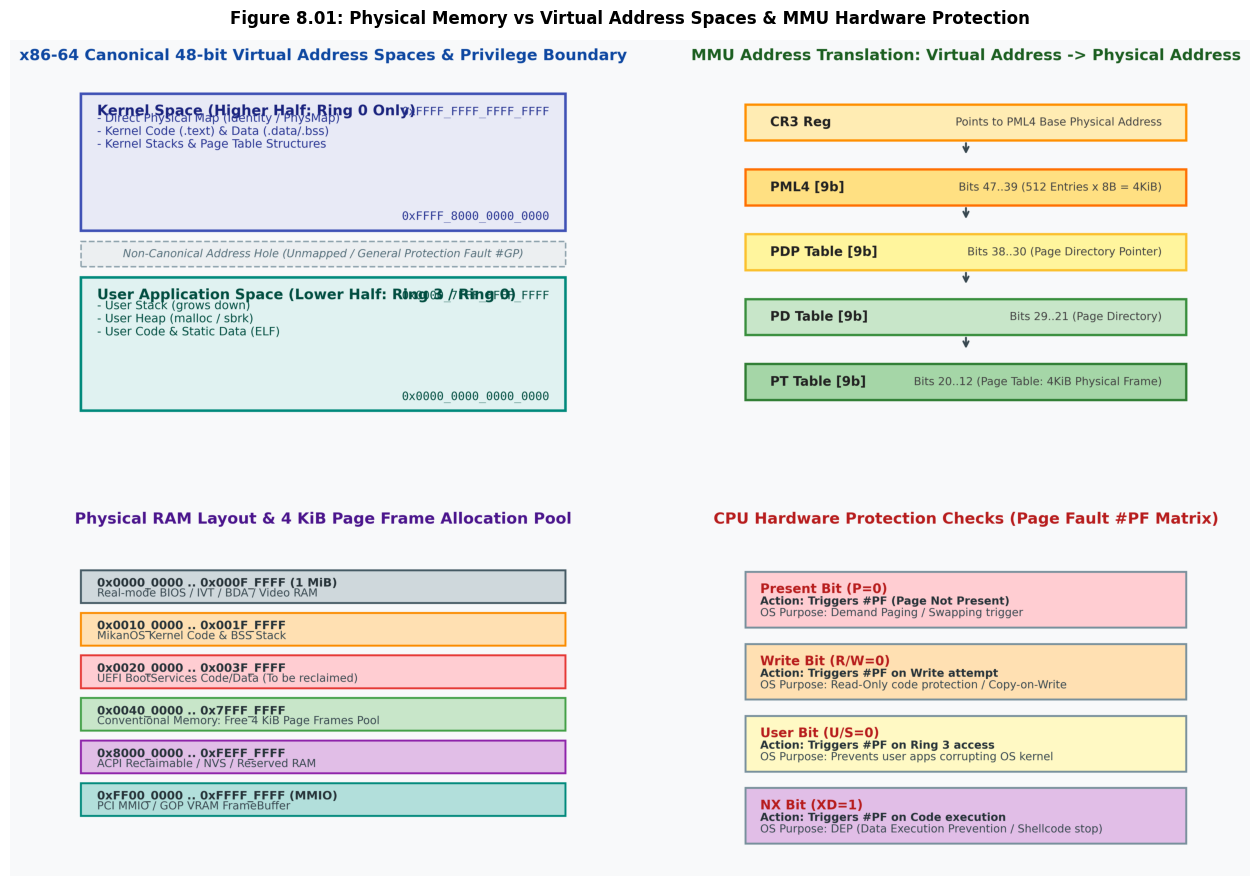

In [3]:
# === Figure 8.01: 物理メモリ vs 仮想メモリの全体アーキテクチャ & MMU 変換モデル ===
from common import plot_fig8_01_physical_vs_virtual_memory_architecture

# 1. 高解像度プロット生成 (DPI 300)
fig1_path = plot_fig8_01_physical_vs_virtual_memory_architecture("result/fig8_01_physical_vs_virtual_memory_architecture.png")
print(f"✅ Figure 8.01 を生成・保存しました: {fig1_path}")

# 2. 生成画像のインライン表示
img1 = plt.imread(fig1_path)
plt.figure(figsize=(16, 11), dpi=100)
plt.imshow(img1)
plt.axis("off")
plt.title("Figure 8.01: Physical Memory vs Virtual Address Spaces & MMU Hardware Protection",
          fontsize=12, fontweight="bold", pad=12)
plt.show()


---

## 4. x86-64 メモリ管理ハードウェアの階層構造（セグメンテーション & ページング）

x86-64 アーキテクチャには、歴史的な経緯から **「セグメンテーション（*Segmentation*）」** と **「ページング（*Paging*）」** という 2 つのメモリ管理機構が多重に存在します。
64ビット Long Mode における両者の役割分担を整理しておきましょう：

```text
 論理アドレス (Logical Address)
   [セグメントセレクタ : オフセット]
                 │
                 ▼
      ┌──────────────────────┐
      │ セグメンテーション  │ ◄─── GDT (Global Descriptor Table)
      │ (Base=0, Limit=無効) │      特権レベル (DPL=0 vs DPL=3) & コード/データ属性
      └──────────────────────┘
                 │
                 ▼
  リニア / 仮想アドレス (Linear / Virtual Address)
                 │
                 ▼
      ┌──────────────────────┐
      │      ページング      │ ◄─── CR3 レジスタ (PML4 ページテーブル)
      │   (4-Level Paging)   │      4 KiB / 2 MiB 単位のアドレス変換・アクセス保護
      └──────────────────────┘
                 │
                 ▼
  物理アドレス (Physical Address) [DRAM]
```

### 4.1 64ビット Long Mode におけるセグメンテーション（GDT）の真実

32ビット Protected Mode までは、セグメンテーションによってベースアドレスを加算してメモリを区切っていました。
しかし、**64ビット Long Mode ではベースアドレスは強制的に 0、リミットチェックは無効化** され、メモリ空間はフラットモデル（平坦モデル）となりました。

では、なぜ第8章（8.5節）で GDT（Global Descriptor Table）を設定しなければならないのでしょうか？
理由は以下の 2 点です：

1. **実行特権レベル（DPL: Descriptor Privilege Level）の決定**:
   - CPU が現在 Ring 0（カーネル特権）で動いているのか、Ring 3（ユーザー権限）で動いているのかは、コードセグメントレジスタ `CS` の下位 2 ビット（CPL: Current Privilege Level）で決まります。
2. **64ビットコード実行属性の有効化**:
   - `L` ビット（Long Mode Code）や `D` ビットを設定し、CPU に「ここは 64ビット Long Mode のネイティブコードを実行するセグメントである」と明示する必要があります。

### 4.2 恒等マッピング（Identity Mapping）の意義

第8章（8.6節）で構築する初期ページテーブルでは、**「仮想アドレス $X$ をそのまま物理アドレス $X$ へ変換するマッピング（恒等マッピング / *Identity Mapping*）」** を設定します。

なぜ初期段階では仮想アドレスと物理アドレスを同一にするのでしょうか？
- ページングを有効化（`CR3` にテーブルをセット）した瞬間に、CPU の命令ポインタ `RIP` やスタックポインタ `RSP` が指しているアドレスが突然別の場所に化けてしまうと、CPU は即座に暴走・トリプルフォールトでリセットしてしまいます。
- 恒等マッピングを行っておくことで、ページング有効化の前後で全く同じアドレスのままコードの実行をシームレスに継続できるのです。


---

## 5. MikanOS 第8章「メモリ管理」の全体ロードマップ

第8章「メモリ管理」は、全7節にわたって OS カーネルが自らの足で立ち上がり、ファームウェア依存を完全に断ち切るための基盤を整える極めてスリリングな章です。全体の流れを確認しておきましょう：

```mermaid
flowchart TD
    S1["8.1 メモリ管理の全体像 (本節)
PMM vs VMM, ビットマップ数理, 4階層ページング"] --> S2["8.2 UEFIメモリマップのカーネル引き渡し (day08a)
GetMemoryMap() の結果をカーネル引数で渡す"]
    S2 --> S3["8.3 データ構造の退避 (day08b)
IDT や xHCI リングバッファを UEFI 領域から安全退避"]
    S3 --> S4["8.4 スタック領域の切り替え
UEFI スタックからカーネル .bss 1MiB 独自スタックへ RSP 移動"]
    S4 --> S5["8.5 GDT (セグメンテーション) の再構築
Null, Kernel CS=0x08, Kernel SS=0x10 の登録と LGDT"]
    S5 --> S6["8.6 64 GiB 恒等ページングの設定
2 MiB ラージページによる初期ページテーブル構築と CR3 ロード"]
    S6 --> S7["8.7 BitmapMemoryManager の実装 (day08c)
4 KiB 物理ページフレームの First-Fit 割り当て・解放完成"]
```


✅ Figure 8.03 を生成・保存しました: result/fig8_03_chapter8_memory_subsystem_roadmap.png


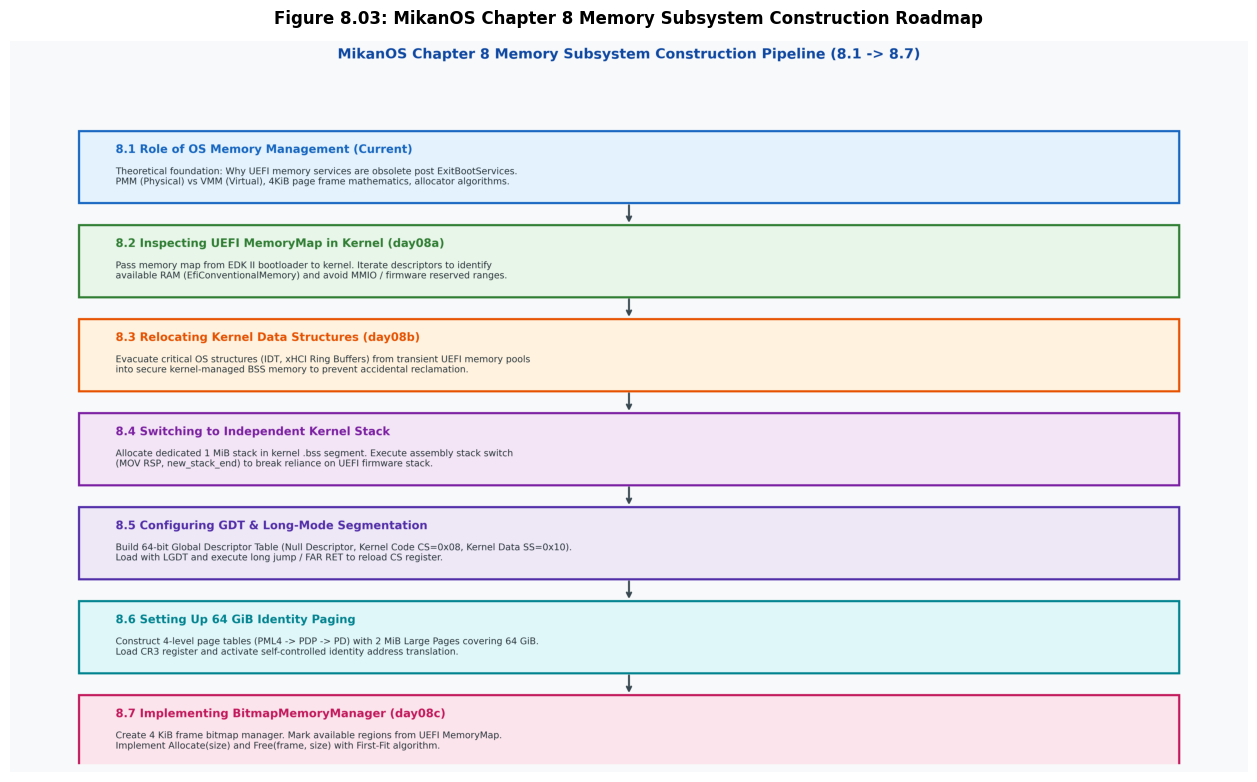

In [4]:
# === Figure 8.03: 第8章 メモリサブシステム構築パイプラインと状態遷移ロードマップ ===
from common import plot_fig8_03_chapter8_memory_subsystem_roadmap

# 1. 高解像度プロット生成 (DPI 300)
fig3_path = plot_fig8_03_chapter8_memory_subsystem_roadmap("result/fig8_03_chapter8_memory_subsystem_roadmap.png")
print(f"✅ Figure 8.03 を生成・保存しました: {fig3_path}")

# 2. 生成画像のインライン表示
img3 = plt.imread(fig3_path)
plt.figure(figsize=(16, 9.5), dpi=100)
plt.imshow(img3)
plt.axis("off")
plt.title("Figure 8.03: MikanOS Chapter 8 Memory Subsystem Construction Roadmap",
          fontsize=12, fontweight="bold", pad=12)
plt.show()


---

## 6. C++20 による物理メモリ管理・アドレス変換のスタンドアロン検証

ホスト環境（Linux / Colab）上で、4 KiB ページフレームの境界アライメント演算、48ビット仮想アドレスの 4階層インデックス分解、および `BitmapMemoryManager` のコアロジックを C++20 で厳密に検証します。

検証ソースコードは [`src/ch08/memory_role_sim.cpp`](../src/ch08/memory_role_sim.cpp) に配備されています。


In [5]:
# === C++20 検証コードのコンパイルと実行 ===
import subprocess

cpp_source = "src/ch08/memory_role_sim.cpp"
bin_target = "src/ch08/memory_role_sim"

# 1. コンパイル実行 (-std=c++20 -O2 -Wall -Wextra)
compile_cmd = f"g++ -std=c++20 -O2 -Wall -Wextra -pedantic {cpp_source} -o {bin_target}"
res = subprocess.run(compile_cmd, shell=True, capture_output=True, text=True)
if res.returncode != 0:
    print("❌ コンパイルエラー:\n", res.stderr)
else:
    print("⚡ C++20 スタンドアロンバイナリのビルドに成功しました！")
    # 2. 実行とアサーション検証
    run_res = subprocess.run(f"./{bin_target}", shell=True, capture_output=True, text=True)
    print(run_res.stdout)
    assert run_res.returncode == 0, "C++20 単体テスト実行失敗"


❌ コンパイルエラー:
 cc1plus: fatal error: src/ch08/memory_role_sim.cpp: No such file or directory
compilation terminated.



---

## 7. Python シミュレータによる MMU 仮想アドレス変換 & #PF 例外の対話的検証

`common/os_sim.py` に実装された `PhysicalVsVirtualMemorySim` を使い、仮想アドレスから物理アドレスへの変換および、権限違反（書き込み禁止、ユーザー権限違反、実行禁止）が発生した際の CPU ページフォルト（`#PF`）送出動作を対話的に実験してみましょう。


In [6]:
# === PhysicalVsVirtualMemorySim による MMU アドレス変換と #PF 発生実験 ===
from common import (
    PageFrameAddressMath,
    PhysicalVsVirtualMemorySim,
    PageFaultType,
    PageFaultException
)

# 1. 仮想 MMU と物理ページフレームプールの初期化 (1,024 物理フレーム = 4 MiB)
mmu_sim = PhysicalVsVirtualMemorySim(total_physical_pages=1024)

# 2. 物理ページフレームを 2 つ確保
frame_k = mmu_sim.allocate_physical_frame() # フレーム 0
frame_u = mmu_sim.allocate_physical_frame() # フレーム 1
print(f"Allocated Physical Frames: Kernel Frame = {frame_k}, User Frame = {frame_u}")

# 3. ページテーブルにマッピング登録
# - 仮想アドレス 0xFFFF_8000_0000_1000 (Kernel Read-Only Page) -> 物理フレーム 0
mmu_sim.map_page(0xFFFF800000001000, frame_k, is_user_space=False, writable=False, user_accessible=False)

# - 仮想アドレス 0x0000_0000_0040_0000 (User Writable Page) -> 物理フレーム 1
mmu_sim.map_page(0x0000000000400000, frame_u, is_user_space=True, writable=True, user_accessible=True)

# 4. 正常なアドレス変換テスト
phys_addr = mmu_sim.translate(0x0000000000400234, is_user_mode=True, is_write=True, is_user_space=True)
print(f"✅ User Write: VAddr 0x0000000000400234 -> PhysAddr 0x{phys_addr:08X}")

# 5. 異常アクセス1: 存在しないページへのアクセス (#PF: Page Not Present)
try:
    mmu_sim.translate(0x0000000000500000, is_user_mode=True, is_user_space=True)
except PageFaultException as e:
    print(f"🛡️ CPU Trapped [Page Not Present]: {e}")

# 6. 異常アクセス2: ユーザーモードからカーネルページへのアクセス (#PF: User Access Violation)
try:
    mmu_sim.translate(0xFFFF800000001000, is_user_mode=True, is_user_space=False)
except PageFaultException as e:
    print(f"🛡️ CPU Trapped [User Access Violation]: {e}")

# 7. 異常アクセス3: 読み取り専用ページへの書き込み (#PF: Write Protection Violation)
try:
    mmu_sim.translate(0xFFFF800000001000, is_user_mode=False, is_write=True, is_user_space=False)
except PageFaultException as e:
    print(f"🛡️ CPU Trapped [Write Protection]: {e}")


Allocated Physical Frames: Kernel Frame = 0, User Frame = 1
✅ User Write: VAddr 0x0000000000400234 -> PhysAddr 0x00001234
🛡️ CPU Trapped [Page Not Present]: #PF at RIP=0x1000, CR2=0x500000: Page Not Present (Bit 0 = 0)
🛡️ CPU Trapped [User Access Violation]: #PF at RIP=0x1000, CR2=0xFFFF800000001000: User-mode accessing Supervisor Page (Bit 2 = 1)
🛡️ CPU Trapped [Write Protection]: #PF at RIP=0x1000, CR2=0xFFFF800000001000: Write Violation / Read-Only Page (Bit 1 = 1)


---

## 8. 理解度チェック & まとめ

### 8.1 3問セルフチェッククイズ

**Q1: UEFI の `ExitBootServices()` 呼び出し以降、なぜ OS カーネルはファームウェアのメモリ割り当て関数（`AllocatePages` 等）を使えなくなるのですか？**
> **A1**: `ExitBootServices()` が成功した瞬間、UEFI の Boot Services コード領域・データ領域は OS へ明け渡す解放対象となり、すべての Boot Services API は恒久的に無効化されるためです。呼べば未定義命令や CPU 例外でハングします。

**Q2: 4 KiB ページフレームを管理するビットマップ方式において、4 GiB の物理 RAM を管理するのに必要なビットマップのサイズは何バイト（何 KiB）ですか？**
> **A2**: 4 GiB のフレーム数は $4 	imes 1024^3 / 4096 = 1,048,576$ フレームです。1 フレームを 1 ビットで表すため、$1,048,576 / 8 = 131,072$ バイト（**ちょうど 128 KiB**）となります。全体のわずか約 0.003% という極小のオーバヘッドです。

**Q3: x86-64 の 4階層ページングにおいて、64ビット仮想アドレスはどのように分解されますか？**
> **A3**: 上位 16 ビット（ビット 63..48）がビット 47 の符号拡張（Canonical 検査）、続く 36 ビットが 9 ビットずつ 4 階層のインデックス（PML4, PDP, PD, PT 各 512 エントリ）、最下位 12 ビット（ビット 11..0）が 4 KiB ページ内オフセット（0x000..0xFFF）に分解されます。

---

### 8.2 本節のまとめと次節（8.2節）への展望

本節では、OS 自前メモリ管理の動機、物理メモリ管理（4 KiB ページフレームとビットマップ数理）、仮想メモリ管理（MMU と 4階層ページングのビット構造）、および第8章の構築ロードマップを学びました。

次節 **「8.2 UEFIメモリマップ (`osbook_day08a`)」** では、ブートローダから渡されたメモリマップ構造体（`MemoryMap`）をカーネル側で実際に走査し、どの物理アドレスが利用可能（`EfiConventionalMemory`）で、どの物理アドレスが予約領域（MMIO / ファームウェア領域）なのかをカーネル自身が判別する実装へと進みます！
